# Figure 6c. Conservation of AD loci by colocalization class

Mean Zoonomia primate PhastCons score per AD locus unit, for AD GWAS credible sets with no TransMap colocalization (AD-only, n = 53), colocalization CoS involving only *trans* outcomes (AD-*trans*, n = 16), and CoS involving both *cis* and *trans* outcomes (AD-*cis*-*trans*, n = 78). Each AD-only credible set and each colocalization CoS is one unit; its score is the mean over its scored variants. Violins show the density, boxes the interquartile range, white diamonds the median. Pairs are compared with two-sided Wilcoxon rank-sum tests (normal approximation); following the author's figure code, stars use the nominal P value (* P < 0.05, ** P < 0.01, *** P < 0.001) and only pairs with P < 0.05 get a bracket. BH-adjusted P values are printed for reference (AD-only vs AD-*trans* is not significant after BH correction).

Input: `data/Figure_6c_conservation_scores.rds`.

In [1]:
suppressPackageStartupMessages({
  library(ggplot2)
})
cons <- readRDS("data/Figure_6c_conservation_scores.rds")
head(cons)
table(cons$category)

,unit_id,category,n_variants,n_scored,conservation_score
,<chr>,<fct>,<int>,<int>,<dbl>
1,AD_only_chr10_cs6,AD-only,25,25,0.1713200
2,AD_only_chr11_cs7,AD-only,1,1,0.0020000
3,AD_only_chr11_cs8,AD-only,9,9,0.1174444
4,AD_only_chr11_cs9,AD-only,16,16,0.1708125
5,AD_only_chr14_cs15,AD-only,53,53,0.0374717
6,AD_only_chr14_cs16,AD-only,5,5,0.1550000



     AD-only     AD-trans AD-cis-trans 
          53           16           78 

    group1       group2    median1    median2      p_value    p_adj_BH sig
1  AD-only     AD-trans 0.05800000 0.01358333 0.0426248676 0.063937301   *
2  AD-only AD-cis-trans 0.05800000 0.12338462 0.2078963206 0.207896321  ns
3 AD-trans AD-cis-trans 0.01358333 0.12338462 0.0006819804 0.002045941 ***


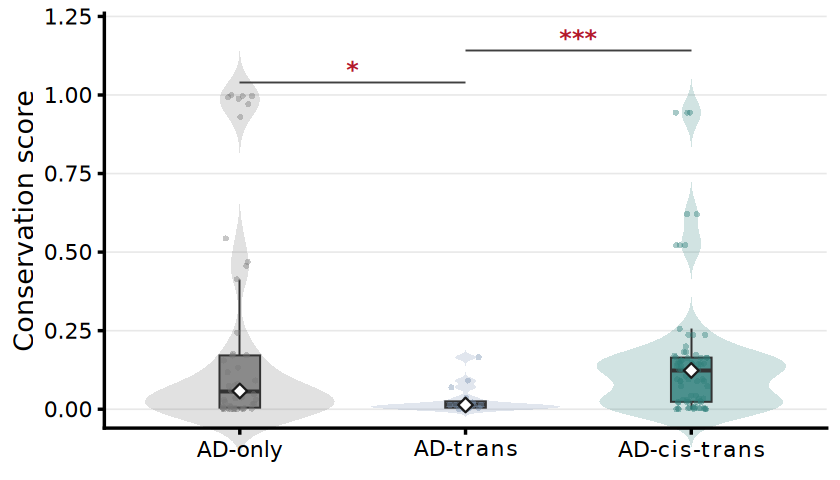

In [2]:
levs <- levels(cons$category)
tests <- do.call(rbind, lapply(combn(levs, 2, simplify = FALSE), function(pr) {
  a <- cons$conservation_score[cons$category == pr[1]]
  b <- cons$conservation_score[cons$category == pr[2]]
  data.frame(group1 = pr[1], group2 = pr[2], median1 = median(a), median2 = median(b),
             p_value = wilcox.test(a, b, exact = FALSE)$p.value)
}))
tests$p_adj_BH <- p.adjust(tests$p_value, method = "BH")
tests$sig <- cut(tests$p_value, c(-Inf, 0.001, 0.01, 0.05, Inf), labels = c("***", "**", "*", "ns"))
print(tests)

ymax <- max(cons$conservation_score)
step <- ymax * 0.10
sig_pairs <- subset(tests, p_value < 0.05)
sig_pairs$x1 <- match(sig_pairs$group1, levs)
sig_pairs$x2 <- match(sig_pairs$group2, levs)
sig_pairs <- sig_pairs[order(abs(sig_pairs$x2 - sig_pairs$x1), sig_pairs$x1), ]
sig_pairs$y <- ymax * 1.04 + step * (seq_len(nrow(sig_pairs)) - 1)

cat_colors <- c("AD-only" = "#777777", "AD-trans" = "#7991B1", "AD-cis-trans" = "#2F7F7B")
cat_labels <- c("AD-only" = "'AD-only'", "AD-trans" = "'AD-'*italic(trans)",
                "AD-cis-trans" = "'AD-'*italic(cis)*'-'*italic(trans)")

p <- ggplot(cons, aes(category, conservation_score, fill = category)) +
  geom_violin(scale = "width", trim = FALSE, alpha = 0.22, color = NA, width = 0.84) +
  geom_boxplot(width = 0.18, outlier.shape = NA, alpha = 0.82, linewidth = 0.42, color = "grey20") +
  geom_point(aes(color = category), position = position_jitter(width = 0.075, height = 0, seed = 2026),
             size = 1.45, alpha = 0.42, stroke = 0) +
  stat_summary(fun = median, geom = "point", shape = 23, size = 2.8, fill = "white", color = "grey10") +
  geom_segment(data = sig_pairs, aes(x = x1, xend = x2, y = y, yend = y), inherit.aes = FALSE,
               linewidth = 0.4, color = "grey25") +
  geom_text(data = sig_pairs, aes(x = (x1 + x2) / 2, y = y + step * 0.12, label = sig), inherit.aes = FALSE,
            color = "#B2182B", size = 5, fontface = "bold", vjust = 0) +
  scale_fill_manual(values = cat_colors, guide = "none") +
  scale_color_manual(values = cat_colors, guide = "none") +
  scale_x_discrete(labels = function(x) parse(text = cat_labels[x])) +
  labs(x = NULL, y = "Conservation score") +
  coord_cartesian(ylim = c(0, max(sig_pairs$y) + step * 0.6), clip = "off") +
  theme_classic(base_size = 16) +
  theme(panel.grid.major.y = element_line(color = "grey91", linewidth = 0.35))

options(repr.plot.width = 7, repr.plot.height = 4)
p